# The local plane interface approximation

A thin optical element, such as a microlens array, a diffuser, a Fresnel
lens or a surface relief grating, is usually put into a wave optical model
with the **thin element approximation (TEA)**. Its height profile $h(x, y)$
becomes a phase screen in a single plane,

$$t(x, y) = \exp\big(i k_0 (n_2 - n_1) h(x, y)\big),$$

as if the light crossed the profile straight along $z$. That is exact for
a flat plate and good for gentle profiles. It ignores that the light is
refracted inside the profile, that the phase picked up depends on the
angle of incidence, and that the Fresnel transmission and the polarization
depend on the local slope.

The **local plane interface approximation (LPIA)**, used for structured
interfaces by the field tracing software VirtualLab Fusion and in the
group of F. Wyrowski and H. Gross in Jena, keeps the field but treats the
interface locally exactly. Every point of the incident field is a local
plane wave. Where it meets the surface, the surface is replaced by its
tangent plane, and the plane wave is refracted and transmitted exactly as
at an infinite plane interface: law of refraction, Fresnel matrix
$(t_s, t_p)$ at the local angle of incidence. Behind the interface the
local plane waves are summed up again into a field.

In pyoptics, notebook [460 (field tracing)](460_field_tracing.ipynb)
already uses this for lens systems: `ft.Trace` takes a field through the
surfaces of a `raytrace.System` that way. This notebook adds the LPIA for
single interfaces and thin structured elements inside a field tracing
chain:

- `ft.LocalPlaneInterface(h, n_after)`: a curved or structured interface
  $z = h(x, y)$ between the field's medium and `n_after`;
- `ft.ThinElement(h, n, method="lpia", face=...)`: a drop-in replacement of
  the TEA for a plate with one structured face.

We check them against exact references (Fresnel's formulas, the series
solution of a dielectric cylinder, rigorous coupled-wave analysis) and
against the TEA and the wave propagation method of notebook
[105 (wave propagation method)](105_wave_propagation_method.ipynb), to see where the LPIA is
worth its (small) extra cost.

In [1]:
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import fieldtrace as ft
from pyoptics import sketch
from pyoptics.analytical import cylinder_field
from pyoptics.interfaces import T_s, T_p
from pyoptics.litho.rcwa import Layer, rcwa
from pyoptics.wpm import wpm_propagate_z

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "0.45"
COLORS = {"TEA": RED, "LPIA": BLUE, "WPM": GREEN, "RCWA": "k", "exact": "k"}
warnings.simplefilter("ignore", RuntimeWarning)
t_start = time.time()

wl = 0.5          # wavelength [µm]; lengths in µm in this notebook
k0 = 2*np.pi/wl
n_glass = 1.5

## 1. What the LPIA does

The sketches show light coming from glass on the left through a
sinusoidal surface into air. The TEA (left) lets every ray cross the
profile straight: the ray picks up the optical thickness of the glass as
a phase, all in one plane, with no deflection and no dependence on the
angle. In the LPIA (right) each sample of the incident field becomes a
ray along its local wave vector. At the surface the ray sees only the
tangent plane (dark grey): it is refracted by the law of refraction, and
its field vector is multiplied by the Fresnel coefficients of that plane.
The rays then go straight on to an output plane just behind the profile,
where the field is collected again by ray field summation
(`raywave.rays_to_field()`), with the energy law of the ray tubes and the
optical path as the phase. The difference between the two grows with the
slope of the profile, i.e. with depth over period.

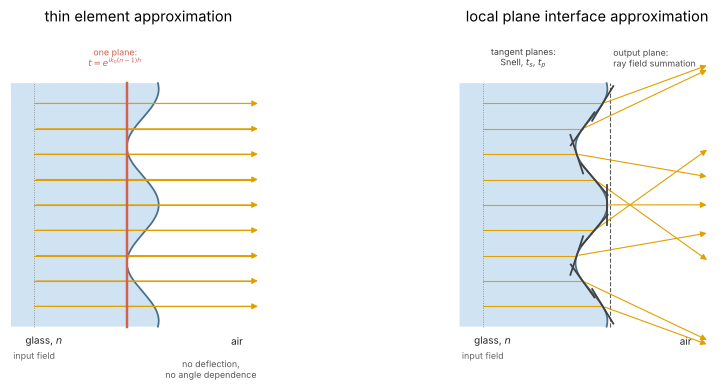

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sketch.lpia_principle(axes[0], "tea", title="thin element approximation")
sketch.lpia_principle(axes[1], "lpia", title="local plane interface approximation")
plt.tight_layout(); plt.show()

## 2. A tilted plane: exact

For a plane interface the LPIA is not an approximation at all. A plane
wave hitting a plane tilted by $\theta$ must leave in the direction of the
law of refraction, with the power transmittance $T_s$ or $T_p$ of
Fresnel's formulas. We send a broad, flat beam (soft edges) through
`LocalPlaneInterface(lambda x: x*tan(theta), 1.5)` and measure the
direction of the transmitted beam from its linear phase and its power
transmittance from the $z$ component of the Poynting vector,
$n_2 \cos\delta \int |E|^2\,dx$ against $n_1 \int |E_\mathrm{in}|^2\,dx$
($\delta$: angle of the transmitted beam to the $z$ axis, $|E|^2$
including $E_z$, which the p polarized beam has).

In [3]:
x = np.linspace(-60, 60, 601)
A = np.exp(-(x/40)**10)
print("theta   delta (Snell)  delta (LPIA)   T_s exact  T_s LPIA   T_p exact  T_p LPIA")
for th_deg in (0, 15, 30, 45, 60):
    th = np.radians(th_deg)
    row = []
    for pol in ("s", "p"):
        src = ft.Field(np.stack([A*(pol == "p"), A*(pol == "s")], -1), x, None, wl)
        step = ft.LocalPlaneInterface(lambda X: 20 + np.tan(th)*X, n_glass, distance=60.0)
        out = ft.Chain([step]).run(src, polarization="vector").field
        delta = -np.arcsin(out.beta[0]/(k0*n_glass))
        E2 = out.irradiance(include_z=True)
        T = n_glass*np.cos(delta)*np.sum(E2)*(out.x[1] - out.x[0])/(np.sum(A**2)*(x[1] - x[0]))
        row.append((delta, T))
    th2 = np.arcsin(np.sin(th)/n_glass)
    print("{:4d}°   {:8.3f}°     {:8.3f}°     {:.5f}    {:.5f}    {:.5f}    {:.5f}".format(
        th_deg, np.degrees(th - th2), np.degrees(row[0][0]), T_s(th, 1, n_glass), row[0][1],
        T_p(th, 1, n_glass), row[1][1]))

theta   delta (Snell)  delta (LPIA)   T_s exact  T_s LPIA   T_p exact  T_p LPIA
   0°      0.000°       -0.000°     0.96000    0.96000    0.96000    0.96000
  15°      5.064°        5.064°     0.95616    0.95615    0.96367    0.96367
  30°     10.529°       10.529°     0.94220    0.94219    0.97475    0.97474
  45°     16.874°       16.874°     0.90799    0.90798    0.99153    0.99153
  60°     24.736°       24.736°     0.82343    0.82342    0.99820    0.99819


Directions and transmittances agree to the accuracy of the ray summation
on the grid. The transmitted field is also vectorial: the p polarized beam
behind the tilted plane has an $E_z$ component, and a curved surface turns
part of a linearly polarized beam into the cross polarization, as the
lens surfaces in notebook [460 (field tracing)](460_field_tracing.ipynb)
do (the test suite checks `LocalPlaneInterface` against `Trace` for a
thick lens, including that cross-polarized part).

## 3. Surface relief gratings against rigorous coupled-wave analysis

A periodic profile diffracts a plane wave into discrete orders, and
rigorous coupled-wave analysis (RCWA, `litho.rcwa`; notebook
[810 (rigorous mask)](810_litho_rigorous_mask.ipynb) uses it for
lithography masks) gives their efficiencies exactly; the profile is cut
into thin lamellar layers. That makes gratings the ideal test case. The
light comes from the glass at normal incidence (TE: $E$ along the
grooves) and leaves into air. We compute the efficiencies of the
transmitted orders

- with the TEA: phase screen $k_0(n - 1)h$ plus the Fresnel transmission
  of a plane interface at normal incidence;
- with the LPIA: `LocalPlaneInterface` over four periods, the field in the
  output plane Fourier transformed into its orders;
- with RCWA (40 layers),

as a function of the period $\Lambda$ over the wavelength, keeping the
depth fixed. The efficiency of order $m$ is the power flux of that plane
wave, $|c_m|^2 \cos\theta_m / n$, relative to the incident one.

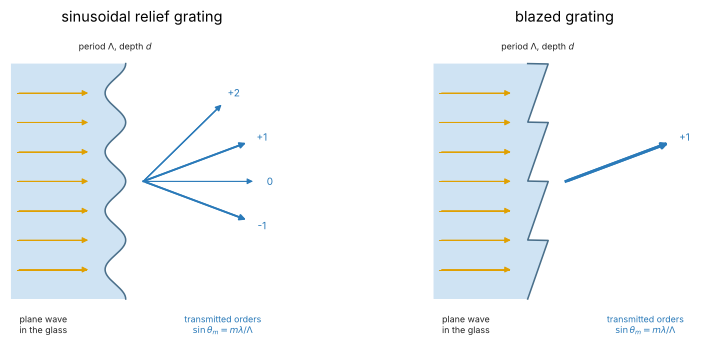

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
sketch.relief_grating_orders(axes[0], "sinusoidal", title="sinusoidal relief grating")
sketch.relief_grating_orders(axes[1], "blazed", title="blazed grating")
plt.tight_layout(); plt.show()

In [5]:
def orders_field(h, P, method, grad=None, M=4, N_per=512, orders=(0, 1, 2)):
    """Transmitted efficiencies of a relief grating h(x) (glass below, light
    from the glass at normal incidence, TE) with the TEA or the LPIA."""
    N = M*N_per
    x = (np.arange(N) + 0.5)*P/N_per - M*P/2
    src = ft.Field(np.stack([0*x, np.ones(N)], -1).astype(complex), x, None, wl, n=n_glass)
    if method == "LPIA":
        chain = ft.Chain([ft.LocalPlaneInterface(h, 1.0, gradient=grad, x_out=x)])
        res = chain.run(src, polarization="vector")
    else:
        chain = ft.Chain([ft.ThinElement(h, n_glass, n_medium=1.0), ft.Interface(1.0, fresnel=True)])
        res = chain.run(src)
    c = np.fft.fft(res.field.E()[1])/N
    eff = [abs(c[(m*M) % N])**2*np.sqrt(max(k0**2 - (2*np.pi*m/P)**2, 0))/k0/n_glass
           for m in orders]
    return np.array(eff), res


def orders_rcwa(glass_segment, P, depth, K=40, orders=(0, 1, 2)):
    """The same rigorously: K lamellar layers, glass_segment(z) = (centre,
    width) of the glass at the height z above the substrate."""
    layers = []
    for z in (np.arange(K) + 0.5)/K*depth:
        c, w = glass_segment(z)
        layers.append(Layer(depth/K, 1.0, [(c, min(w, 0.999*P), n_glass)]))
    res = rcwa(P, layers, wl, n_in=n_glass, n_out=1.0, n_orders=max(12, int(2*P/wl)))
    T = res.efficiencies((0, 1))[1][0]
    return np.array([T[res.m == m][0] for m in orders])


periods = np.array([1.37, 1.83, 2.47, 3.07, 4.11, 5.53, 8.13, 11.3, 16.07])

### A sinusoidal grating

$h = \frac{d}{2}\left(1 + \cos\frac{2\pi x}{\Lambda}\right)$ with
$d = 0.8\ \mu$m, a peak-to-valley phase of 0.8 waves. In the TEA the
efficiencies are those of a sinusoidal phase grating, $J_m^2$ of half the
peak-to-valley phase, independent of the period.

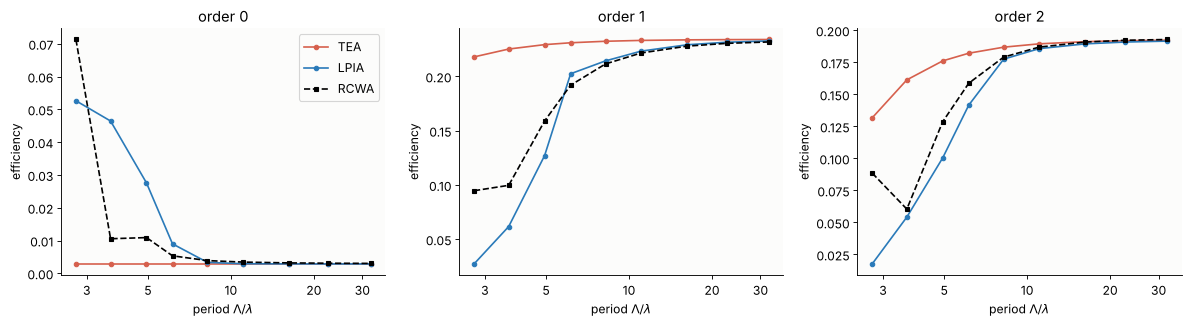

In [6]:
d_sin = 0.8
eff = {"TEA": [], "LPIA": [], "RCWA": []}
times = {"TEA": 0.0, "LPIA": 0.0, "RCWA": 0.0}
notes_sin = {}
for P in periods:
    h = lambda X, P=P: d_sin/2*(1 + np.cos(2*np.pi*X/P))
    for m in ("TEA", "LPIA"):
        t0 = time.time()
        e, res = orders_field(h, P, m)
        times[m] += time.time() - t0
        eff[m].append(e)
        if m == "LPIA":
            notes_sin[P] = res.log[0]["notes"]
    t0 = time.time()
    seg = lambda z, P=P: (0.0, P/np.pi*np.arccos(np.clip(2*z/d_sin - 1, -1, 1)))
    eff["RCWA"].append(orders_rcwa(seg, P, d_sin))
    times["RCWA"] += time.time() - t0
eff = {k: np.array(v) for k, v in eff.items()}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharex=True)
for i, ax in enumerate(axes):
    for m in ("TEA", "LPIA", "RCWA"):
        ax.plot(periods/wl, eff[m][:, i], "o-" if m != "RCWA" else "s--", color=COLORS[m],
                ms=4, lw=1.5, label=m)
    ax.set_xscale("log"); ax.set_xlabel(r"period $\Lambda/\lambda$")
    ax.set_xticks([3, 5, 10, 20, 30]); ax.set_xticklabels(["3", "5", "10", "20", "30"])
    ax.minorticks_off()
    ax.set_title("order {}".format(i)); ax.set_ylabel("efficiency")
axes[0].legend()
plt.tight_layout(); plt.show()

Down to periods of about eight wavelengths the LPIA follows the rigorous
result to a few thousandths, and at six wavelengths to 0.01 to 0.02,
while the TEA is off by 0.02 to 0.04 in the first two orders there (10 to
25 % of their value). The LPIA gets the trend right because the slopes of
the profile tilt and spread the local plane waves: the phase over the
period changes, and the Fresnel losses grow with the local angle of
incidence. Below about five wavelengths the radius of curvature at the
crests and valleys falls below the wavelength (the report says so), light
starts to be totally reflected inside the glass at the steep flanks, and
the LPIA breaks down. At five wavelengths the report of the LPIA step
lists all of it: a third of the power totally reflected, radii of
curvature of the profile down to 0.8 wavelengths, and rays that cross
behind the profile; at six wavelengths only the small radius of
curvature (1.2 wavelengths) remains. There, only a rigorous model will
do. Both approximations are essentially free: the nine periods take a
few hundredths of a second with the TEA and the LPIA, about five seconds
with RCWA, which needs many orders for the large periods.

### A blazed grating

A sawtooth $h = d\,(x \bmod \Lambda)/\Lambda$ of depth
$d = \lambda/(n - 1)$ is a blazed grating: in the TEA it sends all the
light into the first order (apart from the Fresnel loss and the obliquity
of the order). Its vertical steps are what the LPIA cannot model exactly:
light near a step would hit the vertical wall of the next tooth or pass
through it. `LocalPlaneInterface` detects the steps (from the jump of the
height between neighbouring rays) and drops the ray there, and the report
lists the facets that are too narrow for the approximation. This kind of
profile is the zone structure of a Fresnel lens or a kinoform, as in
notebooks [421 (Fresnel lenses)](421_fresnel_lenses.ipynb) and
[422 (hybrid diffractive lenses)](422_hybrid_diffractive_lenses.ipynb).

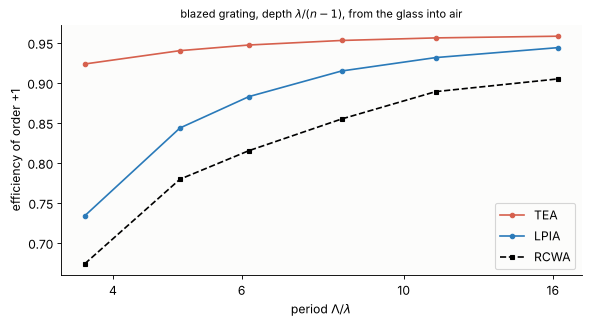

In [7]:
d_bl = wl/(n_glass - 1)
blaze = {"TEA": [], "LPIA": [], "RCWA": []}
p_blaze = periods[1:7]            # RCWA of the staircase stops converging beyond ~16 wavelengths
for P in p_blaze:
    h = lambda X, P=P: d_bl*np.mod(X, P)/P
    g = lambda X, P=P: np.full_like(X, d_bl/P)
    blaze["TEA"].append(orders_field(h, P, "TEA")[0][1])
    blaze["LPIA"].append(orders_field(h, P, "LPIA", grad=g)[0][1])
    seg = lambda z, P=P: (P - P*(1 - z/d_bl)/2, P*(1 - z/d_bl))
    blaze["RCWA"].append(orders_rcwa(seg, P, d_bl)[1])

fig, ax = plt.subplots(figsize=(7.5, 4.2))
for m in ("TEA", "LPIA", "RCWA"):
    ax.plot(p_blaze/wl, blaze[m], "o-" if m != "RCWA" else "s--", color=COLORS[m], ms=4, label=m)
ax.set_xscale("log"); ax.set_xlabel(r"period $\Lambda/\lambda$"); ax.set_ylabel("efficiency of order +1")
ax.set_xticks([4, 6, 10, 16]); ax.set_xticklabels(["4", "6", "10", "16"]); ax.minorticks_off()
ax.set_title("blazed grating, depth $\\lambda/(n-1)$, from the glass into air", fontsize=10)
ax.legend(); plt.tight_layout(); plt.show()

The TEA misses the drop of the efficiency at small periods almost
entirely (0.92 at four wavelengths, where RCWA gives 0.67). The LPIA gets
most of it (0.73): the refraction at the tilted facets deflects the light
slightly off the direction of the order, and the Fresnel losses grow with
the angle. A residual of 0.04 to 0.06 remains at all periods: the step
itself, i.e. the shadow of the vertical wall and the diffraction at its
edges, which the LPIA does not model. For stepped profiles an RCWA of one
period (or the FDTD) stays the reference; the LPIA is the better fast
estimate, and the only one of the two that works on a whole aperiodic
element such as a Fresnel lens.

## 4. A rod lens against the exact solution

A dielectric cylinder (radius $a$, $n = 1.5$, axis along $y$) has an exact
series solution (`analytical.cylinder_field()`, used in notebook
[105 (wave propagation method)](105_wave_propagation_method.ipynb) to check the WPM). It is a
hard test for any approximation: the surfaces are strongly curved, the
beam (a flat top of 60 % of the diameter) meets them at up to 37°, and the
focus lies only half a radius behind the rod. We compare the
field just behind the rod, at $z = a + 2\ \mu$m, from

- the TEA: the thickness $2\sqrt{a^2 - x^2}$ as a thin element in the
  plane through the axis, then free space;
- the LPIA chain: `LocalPlaneInterface` for the front surface, the
  spectrum of plane waves through the glass to the axis, the back surface
  with its output plane back on the axis (`distance=0`, see below), then
  the spectrum of plane waves to the observation plane;
- the WPM, with steps of $\lambda/16$ (it converges slowly with the step
  size at this index contrast; with $\lambda/4$ its error is about 0.24).

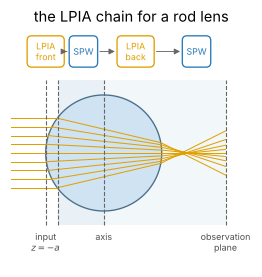

In [8]:
fig, ax = plt.subplots(figsize=(12, 3.6))
sketch.rod_lens_lpia_chain(ax, title="the LPIA chain for a rod lens")
plt.tight_layout(); plt.show()

In [9]:
def rod_lens(a, wpm=True):
    w = 0.6*a
    L = 4*a
    N = int(L/(wl/8)); N += N % 2
    x = np.linspace(-L/2, L/2, N, endpoint=False)
    kx = 2*np.pi*np.fft.fftfreq(N, x[1] - x[0])
    prop = np.abs(kx) < k0
    kz = np.sqrt(np.clip(k0**2 - kx**2, 0, None))
    U = np.fft.fft(np.exp(-(x/w)**8))                  # incident field in the plane z = 0
    incident = lambda z: np.fft.ifft(np.where(prop, U*np.exp(1j*kz*z), 0))
    z_obs = a + 2.0
    out, cost = {}, {}
    t0 = time.time()
    out["exact"] = cylinder_field(x, z_obs, a, n_glass, wl, k_x=kx[prop],
                                  amplitudes=U[prop]/N*np.exp(-1j*kx[prop]*x[0]))
    cost["exact"] = time.time() - t0
    vec = lambda u, z: ft.Field(np.stack([0*u, u], -1), x, None, wl, z=z)
    # TEA in the plane z = 0
    t0 = time.time()
    tea = ft.ThinElement(lambda X: 2*np.sqrt(np.clip(a**2 - X**2, 0, None)), n_glass)
    f = ft.Chain([tea, ft.Propagate(z_obs, method="spw")]).run(vec(incident(0.0), 0.0)).field
    out["TEA"], cost["TEA"] = f.resample(x).E()[1], time.time() - t0
    # LPIA: front surface, waves inside, back surface, waves behind
    t0 = time.time()
    sag = lambda X: np.sqrt(np.clip(a**2 - X**2, 0, None))
    front = ft.LocalPlaneInterface(lambda X: a - sag(X), n_glass)
    res = ft.Chain([front]).run(vec(incident(-a), -a))
    f1 = res.field
    back = ft.LocalPlaneInterface(sag, 1.0, distance=0.0)
    res2 = ft.Chain([ft.Propagate(-f1.z, method="spw"), back]).run(f1)
    f2 = res2.field
    f = ft.Chain([ft.Propagate(z_obs - f2.z, method="spw")]).run(f2).field
    out["LPIA"], cost["LPIA"] = f.resample(x).E()[1], time.time() - t0
    # the same with the output plane of the back surface behind it
    back_b = ft.LocalPlaneInterface(sag, 1.0)
    f2b = ft.Chain([ft.Propagate(-f1.z, method="spw"), back_b]).run(f1).field
    fb = ft.Chain([ft.Propagate(z_obs - f2b.z, method="spw")]).run(f2b).field
    out["LPIA, plane behind"] = fb.resample(x).E()[1]
    log = res.log + res2.log
    if wpm:
        t0 = time.time()
        n_rod = lambda X, Y, z: np.where(X**2 + z**2 < a**2, n_glass, 1.0)
        zz = np.arange(-a, z_obs + 1E-9, wl/16)
        out["WPM"] = wpm_propagate_z(n_rod, incident(-a), x, None, zz, wl)[-1]
        cost["WPM"] = time.time() - t0
    return x, out, cost, log


def rel_error(u, ref, x, a):
    m = np.abs(x) < 1.5*a
    return np.linalg.norm(u[m] - ref[m])/np.linalg.norm(ref[m])


radii = [5.0, 10.0, 25.0, 50.0]
errors, costs = {}, {}
for a in radii:
    x_r, out, cost, log = rod_lens(a)
    for m in ("TEA", "LPIA", "LPIA, plane behind", "WPM"):
        errors.setdefault(m, []).append(rel_error(out[m], out["exact"], x_r, a))
    for m in cost:
        costs.setdefault(m, []).append(cost[m])
    if a == 25.0:
        x25, out25, log25 = x_r, out, log

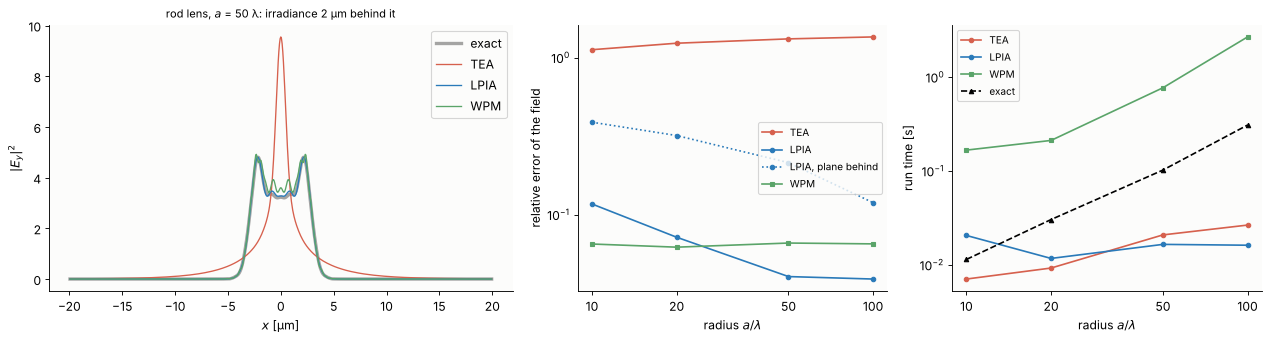

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4), gridspec_kw={"width_ratios": [1.5, 1, 1]})
ax = axes[0]
sel = np.abs(x25) < 20
ax.plot(x25[sel], np.abs(out25["exact"][sel])**2, color="k", lw=3, alpha=0.35, label="exact")
for m in ("TEA", "LPIA", "WPM"):
    ax.plot(x25[sel], np.abs(out25[m][sel])**2, color=COLORS[m], lw=1.2, label=m)
ax.set_xlabel("$x$ [µm]"); ax.set_ylabel("$|E_y|^2$")
ax.set_title("rod lens, $a$ = 50 λ: irradiance 2 µm behind it", fontsize=10)
ax.legend()
ax = axes[1]
for m, ls in (("TEA", "o-"), ("LPIA", "o-"), ("LPIA, plane behind", "o:"), ("WPM", "s-")):
    ax.plot(np.array(radii)/wl, errors[m], ls, color=COLORS.get(m, BLUE), ms=4, label=m)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("radius $a/\\lambda$"); ax.set_ylabel("relative error of the field")
ax.set_xticks([10, 20, 50, 100]); ax.set_xticklabels(["10", "20", "50", "100"]); ax.minorticks_off()
ax.legend(fontsize=9, loc="center right")
ax = axes[2]
for m, ls in (("TEA", "o-"), ("LPIA", "o-"), ("WPM", "s-"), ("exact", "^--")):
    ax.plot(np.array(radii)/wl, costs[m], ls, color=COLORS.get(m, "k"), ms=4, label=m)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("radius $a/\\lambda$"); ax.set_ylabel("run time [s]")
ax.set_xticks([10, 20, 50, 100]); ax.set_xticklabels(["10", "20", "50", "100"]); ax.minorticks_off()
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

The TEA is useless here (errors of 112 % to 135 %): a rod of 50
wavelengths radius is anything but thin. The error of the LPIA chain
falls with the radius, since the surfaces become locally plane on the
scale of the wavelength: 12 % at ten wavelengths, 7 % at twenty, 4 % from
fifty on. That is better than the WPM (6.5 % at all radii), and the LPIA
takes about 0.02 s where the WPM takes one to three seconds, a fiftieth
to a hundredth of the cost (right). What remains are the
multiple reflections inside the rod, which the exact solution contains
and a single pass model does not. For radii of ten to twenty wavelengths
the WPM is as good or better.

**Where to put the output plane.** Behind the back surface the light
converges strongly, and the edge rays of this beam cross each other only
a few micrometres behind the rod. If the output plane of the back
interface is put behind the surface (the default, "behind"), those rays
are carried there with geometrical optics, which fails where they cross;
the report warns about it.

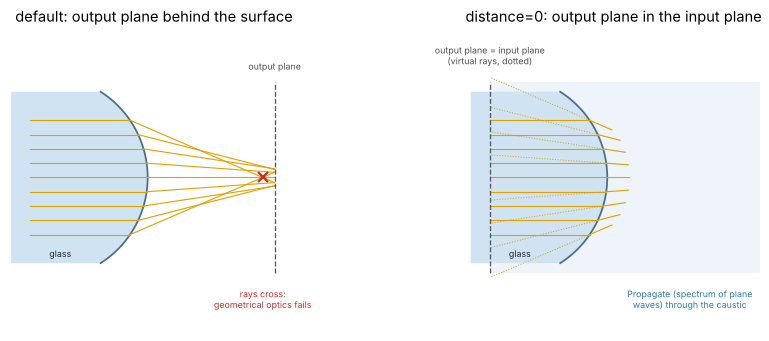

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
sketch.lpia_output_plane(axes[0], "behind", title='default: output plane behind the surface')
sketch.lpia_output_plane(axes[1], "input", title="distance=0: output plane in the input plane")
plt.tight_layout(); plt.show()

The report notes of the back surface, with the output plane on the axis
and with the default:

In [12]:
a = 25.0
kx = 2*np.pi*np.fft.fftfreq(len(x25), x25[1] - x25[0])
U = np.fft.fft(np.exp(-(x25/(0.6*a))**8))
u_front = np.fft.ifft(np.where(np.abs(kx) < k0, U*np.exp(-1j*np.sqrt(np.clip(k0**2 - kx**2, 0, None))*a), 0))
sag = lambda X: np.sqrt(np.clip(a**2 - X**2, 0, None))
inside = ft.Chain([ft.LocalPlaneInterface(lambda X: a - sag(X), n_glass)]).run(
    ft.Field(np.stack([0*u_front, u_front], -1), x25, None, wl, z=-a)).field
inside = ft.Chain([ft.Propagate(-inside.z, method="spw")]).run(inside).field    # to the axis
for name, dist in (("distance=0", 0.0), ("default (behind)", "behind")):
    res = ft.Chain([ft.LocalPlaneInterface(sag, 1.0, distance=dist)]).run(inside)
    print("{:18s} output plane z = {:5.2f} µm: {}".format(name, res.field.z, "; ".join(res.log[0]["notes"]) or "-"))

distance=0         output plane z =  0.00 µm: -
default (behind)   output plane z = 25.00 µm: rays cross between the interface and the output plane (caustic): put the output plane in front of the interface (e.g. distance=0, back to the input plane) and propagate with wave optics


With `distance=0` the transmitted field is propagated *back* to the
input plane of the step (the axis), geometrically: a virtual field whose
rays diverge backwards, so nothing crosses. The spectrum of plane waves
then carries it forward through the caustic. That is the field tracing
principle of notebook [460 (field tracing)](460_field_tracing.ipynb): use
each technique only where it holds. In the table above it reduces the
error by a factor of up to five ("LPIA" against "LPIA, plane behind").

## 5. Which side of a plano-convex lens faces the light?

A classic of lens design: a plano-convex lens focusing a collimated beam
has much less spherical aberration with its curved face towards the beam,
because the refraction is then shared between both faces. The TEA cannot
see the difference at all: it only knows the thickness profile. The LPIA
version of `ThinElement` takes the face that carries the profile as
`face="front"` (towards the light) or `face="back"`.

A cylindrical plano-convex microlens: $R = 100\ \mu$m, $n = 1.5$
($f = 200\ \mu$m), a flat top beam of $\pm 50\ \mu$m (NA about 0.24), a
flat base of 2 µm. As the reference, the WPM takes the field through the
lens with steps of λ/16, and the spectrum of plane waves then through the
focus (as for the TEA and the LPIA). The ray picture shows what to
expect (exaggerated curvature): the marginal rays (red) focus much
shorter than the paraxial ones when the flat face meets the light.

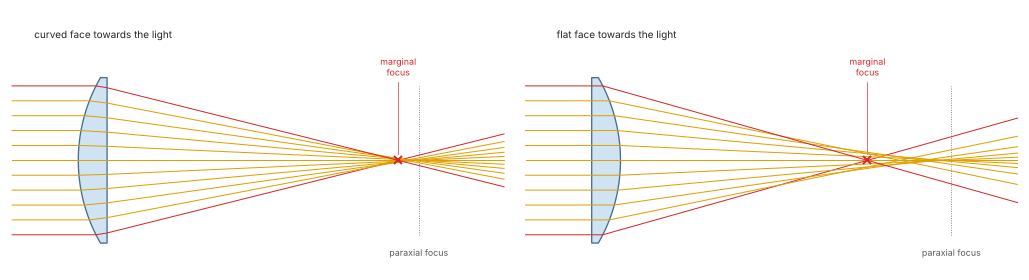

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
sketch.plano_convex_orientation(axes[0], "front")
sketch.plano_convex_orientation(axes[1], "back")
plt.tight_layout(); plt.show()

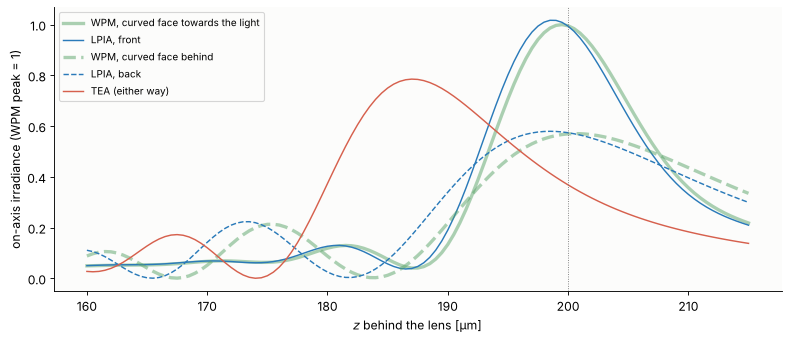

In [14]:
R_pc, base, half = 100.0, 2.0, 55.0
sag_max = R_pc - np.sqrt(R_pc**2 - half**2)
thick = lambda X: base + np.clip(sag_max - (R_pc - np.sqrt(np.clip(R_pc**2 - X**2, 0, None))), 0, None)

L = 160.0
N = int(L/(wl/8)); N += N % 2
x = np.linspace(-L/2, L/2, N, endpoint=False)
u_in = np.exp(-(x/50.0)**12)
src = ft.Field(np.stack([0*u_in, u_in], -1), x, None, wl)
f_par = R_pc/(n_glass - 1)
z_focus = np.linspace(f_par - 40, f_par + 15, 111)
c = N//2


def through_focus(field, z0):
    """On-axis irradiance at the planes z_focus (measured from the plane of the
    lens), field given in the plane z0."""
    I = []
    for z in z_focus:
        f = ft.Chain([ft.Propagate(z - z0, method="spw")]).run(field).field
        I.append(np.abs(f.resample(x).E()[1][c])**2)
    return np.array(I)


curves, timing = {}, {}
for face in ("front", "back"):
    t0 = time.time()
    f = ft.Chain([ft.ThinElement(thick, n_glass, method="lpia", face=face)]).run(src).field
    timing["LPIA " + face] = time.time() - t0
    curves["LPIA " + face] = through_focus(f, 0.0)
    # WPM: glass between z1(x) and z2(x)
    t_tot = base + sag_max
    if face == "front":
        n_pc = lambda X, Y, z: np.where((z > t_tot - thick(X)) & (z < t_tot), n_glass, 1.0)
    else:
        n_pc = lambda X, Y, z: np.where((z > 0) & (z < thick(X)), n_glass, 1.0)
    t0 = time.time()
    zz = np.arange(0, t_tot + 1E-9, wl/16)
    u_w = wpm_propagate_z(n_pc, u_in, x, None, zz, wl)[-1]
    timing["WPM " + face] = time.time() - t0
    f_w = ft.Field(np.stack([0*u_w, u_w], -1), x, None, wl)
    curves["WPM " + face] = through_focus(f_w, t_tot)
t0 = time.time()
f = ft.Chain([ft.ThinElement(thick, n_glass)]).run(src).field
timing["TEA"] = time.time() - t0
curves["TEA"] = through_focus(f, 0.0)

fig, ax = plt.subplots(figsize=(10, 4.4))
norm = curves["WPM front"].max()
for face, ls in (("front", "-"), ("back", "--")):
    ax.plot(z_focus, curves["WPM " + face]/norm, color=GREEN, lw=3, alpha=0.5, ls=ls,
            label="WPM, curved face " + ("towards the light" if face == "front" else "behind"))
    ax.plot(z_focus, curves["LPIA " + face]/norm, color=BLUE, lw=1.3, ls=ls, label="LPIA, " + face)
ax.plot(z_focus, curves["TEA"]/norm, color=RED, lw=1.3, label="TEA (either way)")
ax.axvline(f_par, color=GREY, lw=0.8, ls=":")
ax.set_xlabel("$z$ behind the lens [µm]"); ax.set_ylabel("on-axis irradiance (WPM peak = 1)")
ax.legend(fontsize=9); plt.tight_layout(); plt.show()

The LPIA reproduces the WPM for both orientations: with the curved face
towards the light the focus is bright and close to the paraxial focal
length (dotted), with a peak of 1.02 at 198.5 µm against 1.00 at
199.5 µm from the WPM. With the flat face towards the light its peak drops
to 0.58 (WPM 0.57), the focus is smeared out along the axis, and the marginal
rays, which focus shorter, add the side maxima in front of it. The TEA gives a
third curve that belongs to neither (peak 0.79 at 187 µm): its phase is
that of a thin lens whose aberrations come from the thickness profile
alone. The LPIA takes about 0.01 s per orientation, the WPM about 0.45 s.

## 6. When to use which

| | TEA | LPIA | WPM | RCWA / FDTD |
|---|---|---|---|---|
| model | phase screen in one plane | local plane waves, refraction and Fresnel matrix at the tangent plane | split-step through $n(x, y, z)$ | Maxwell's equations |
| profile scale | slopes ≲ 0.1, depth of a few λ | facets and radii ≳ 5–10 λ, smooth or with few steps | any (converges slowly at high index contrast) | any (RCWA: periodic) |
| polarization, Fresnel | no (normal incidence only) | yes, vectorial | no | yes |
| caustics at the element | yes | no: put the output plane in the input plane (`distance=0`) and propagate | yes | yes |
| cost | one multiplication | one ray trace and ray summation | many FFT steps | expensive |

In practice:

- Keep the TEA for gentle profiles: phase plates, DOEs etched a fraction
  of a wavelength deep with periods of many wavelengths.
- Use `ThinElement(..., method="lpia")` or `LocalPlaneInterface` for
  refractive micro-optics with steep facets: microlens arrays,
  homogenizers, diffusers, refractive beam shapers, Fresnel lenses with
  wide zones, and whenever the orientation of an element, the Fresnel
  losses at large slopes or the polarization matter. It costs about as
  much as the TEA's following propagation step.
- For structures of a few wavelengths (binary CGHs as in notebook
  [503 (CGH null testing of aspheres)](503_cgh_null_testing_aspheres.ipynb),
  subwavelength gratings) and for steps that matter, use RCWA or the
  FDTD; for thick, graded or strongly scattering volumes the WPM.
- Whole lens systems go through `ft.Trace`, which applies the same local
  plane interface approximation surface by surface.

## Summary

- The LPIA replaces the surface at every point by its tangent plane and
  applies the exact plane-interface solution there: law of refraction,
  Fresnel matrix, vectorial polarization, energy conservation of the ray
  tubes. It is exact for plane interfaces.
- For surface relief gratings it follows RCWA down to periods of six to
  eight wavelengths, where the TEA is off by 10 to 25 % in the first
  orders. For blazed (stepped) profiles it catches most of the drop of the
  efficiency at small periods that the TEA misses, with a residual of 0.04
  to 0.06 from the steps.
- For a strongly curved rod lens it is accurate to 4 % from radii of about
  fifty wavelengths, better and far cheaper than the WPM, provided the
  focusing back surface hands its field over in front of the caustic
  (`distance=0`). It distinguishes the two orientations of a plano-convex
  lens, which the TEA cannot.
- Its limits are reported in `ChainResult.report()`: steps, narrow facets,
  small radii of curvature, total internal reflection, shadowing, and rays
  that cross between the interface and the output plane.

## Exercises

- Repeat the sinusoidal grating in TM polarization (`(1, 0)` as the
  Jones vector in RCWA, $E_x$ in the field): where does the LPIA's Fresnel
  matrix make the difference?
- Model a microlens array homogenizer with `ThinElement(method="lpia")`
  and compare the far field with the TEA for lenslets of NA 0.05 and 0.3.
- Feed the blazed grating with an oblique plane wave and find the angle at
  which the LPIA and RCWA part ways.

In [15]:
print("notebook ran in {:.0f} s".format(time.time() - t_start))

notebook ran in 40 s
